# NB01 — Persiapan dataset dan audit warna per citra

Notebook memproses seluruh citra `train` dari kelas target tanpa balancing atau undersampling
kelas. Domain simulasi mengikuti pemetaan kelas sumber dari NB00. Dominant hue dan batas
Otsu–entropy hanya digunakan sebagai audit independen; record `transition` dan `cross_domain`
tetap berada di manifest simulasi.

- **Batas audit warna:** digunakan tanpa perubahan dari NB00.
- **Adaptasi penelitian:** K-Means pada koordinat CIELAB memilih cluster warna dominan;
  circular mean HSV cluster tersebut menjadi dominant hue per citra.
- **Keputusan implementasi:** pHash threshold 8 adalah parameter deduplikasi dan diaudit pada
  0, 2, 4, 6, dan 8. Subset validasi silhouette dibuat satu kali per kelas dan digunakan sama
  untuk seluruh kandidat K.

Alur: audit deduplikasi → pemilihan K → dominant hue → audit RO/transition/GY → manifest.


In [1]:
%pip install opencv-python-headless numpy pandas matplotlib scipy scikit-learn pillow imagehash -q


Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import platform
import sys
from importlib.metadata import version
import time
from pathlib import Path

import cv2
import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.stats import circmean
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

CORE_CANDIDATES = [Path.cwd() / "core", *[path / "core" for path in Path.cwd().parents]]
CORE_DIR = next((path for path in CORE_CANDIDATES if (path / "utils.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("core/utils.py tidak ditemukan")
sys.path.insert(0, str(CORE_DIR))
from utils import ensure_directories, find_research_root, sha256_file, utc_timestamp, write_csv, write_json

RESEARCH_ROOT = find_research_root("notebooks/00/output/color_domain_config.json")
RAW_DIR = RESEARCH_ROOT / "datasets" / "raw" / "fruits"
NB00_CONFIG_PATH = RESEARCH_ROOT / "notebooks" / "00" / "output" / "color_domain_config.json"
OUTPUT_DIR = RESEARCH_ROOT / "notebooks" / "01" / "output"
IMAGE_DIR = RESEARCH_ROOT / "datasets" / "processed" / "fruit_domain"
FIGURES_DIR = OUTPUT_DIR / "figures"
ensure_directories([OUTPUT_DIR, IMAGE_DIR, FIGURES_DIR])

METHOD_VERSION = "dataset-preparation-1.5"
RANDOM_SEED = 42
PHASH_THRESHOLD = 8
PHASH_SENSITIVITY_THRESHOLDS = (0, 2, 4, 6, 8)
TARGET_SIZE = (512, 512)
CLUSTER_SIZE = 224
K_RANGE = range(2, 8)
KMEANS_INIT = "k-means++"
KMEANS_N_INIT = 10
KMEANS_ALGORITHM = "lloyd"
KMEANS_MAX_ITER = 300
KMEANS_TOL = 1e-4
K_SAMPLE_IMAGES = 150
K_PIXELS_PER_IMAGE = 500
SILHOUETTE_SAMPLE = 5_000
IMAGE_CLUSTER_PIXELS = 8_000
REPORT_INTERVAL = 500
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
COMPOSITE_KEY = ["subset", "source_class", "source_file_name"]
PROGRESS_KEY = ["method_version", "processed_records"]
ERROR_AUDIT_KEY = ["error_stage", "source_class", "error_type", "error_message"]

domain_config = json.loads(NB00_CONFIG_PATH.read_text(encoding="utf-8"))
required_config = {"lower_boundary_deg", "upper_boundary_deg", "source_classes", "hue_preprocessing"}
missing_config = sorted(required_config - domain_config.keys())
if missing_config:
    raise ValueError(f"Konfigurasi NB00 tidak lengkap: {missing_config}")

DOMAIN_CLASSES = domain_config["source_classes"]
SOURCE_CLASSES = [name for names in DOMAIN_CLASSES.values() for name in names]
SOURCE_DOMAIN = {name: domain for domain, names in DOMAIN_CLASSES.items() for name in names}
SATURATION_MIN = float(domain_config["hue_preprocessing"]["saturation_min"])
VALUE_MIN = float(domain_config["hue_preprocessing"]["value_min"])
VALUE_MAX = float(domain_config["hue_preprocessing"]["value_max"])
ERROR_PATH = OUTPUT_DIR / "dataset_preparation_errors.csv"
PROGRESS_PATH = OUTPUT_DIR / "dataset_preparation_progress.csv"
DOMAIN_AUDIT_PATH = OUTPUT_DIR / "dataset_preparation_domain_audit.csv"
DEDUP_SENSITIVITY_PATH = OUTPUT_DIR / "deduplication_sensitivity_report.csv"
INPUT_ERROR_AUDIT_PATH = OUTPUT_DIR / "dataset_preparation_error_input_audit.csv"
ERROR_AUDIT_PATH = OUTPUT_DIR / "dataset_preparation_error_audit.csv"
input_errors = pd.read_csv(ERROR_PATH) if ERROR_PATH.exists() else pd.DataFrame()


In [3]:
def software_versions() -> dict[str, str]:
    return {
        "python": platform.python_version(),
        "opencv": cv2.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": version("scipy"),
        "scikit_learn": version("scikit-learn"),
        "pillow": version("Pillow"),
        "imagehash": version("ImageHash"),
    }


def train_images(class_name: str) -> list[Path]:
    train_dir = RAW_DIR / class_name / "train"
    if not train_dir.exists():
        return []
    return sorted(path for path in train_dir.iterdir() if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS)


def perceptual_hash(path: Path):
    with Image.open(path) as image:
        return imagehash.phash(image.convert("RGB"))


def deduplicate_with_hashes(paths: list[Path], hashes: dict[Path, object], threshold: int) -> tuple[list[Path], list[dict]]:
    registry, retained, removed = [], [], []
    for path in paths:
        value = hashes[path]
        match = next(
            ((known_path, abs(value - known_hash)) for known_hash, known_path in registry if abs(value - known_hash) <= threshold),
            None,
        )
        if match:
            removed.append({"duplicate_path": str(path), "similar_to_path": str(match[0]), "hamming_distance": int(match[1])})
        else:
            registry.append((value, path))
            retained.append(path)
    return retained, removed


def color_pixels(image_bgr: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    resized = cv2.resize(image_bgr, (CLUSTER_SIZE, CLUSTER_SIZE), interpolation=cv2.INTER_AREA)
    hsv = cv2.cvtColor(resized, cv2.COLOR_BGR2HSV)
    saturation = hsv[..., 1].astype(np.float32) / 255.0
    value = hsv[..., 2].astype(np.float32) / 255.0
    mask = (saturation >= SATURATION_MIN) & (value >= VALUE_MIN) & (value <= VALUE_MAX)
    normalized_bgr = resized.astype(np.float32) / 255.0
    lab = cv2.cvtColor(normalized_bgr, cv2.COLOR_BGR2LAB)
    hues = hsv[..., 0].astype(np.float32) * 2.0
    return lab[mask], hues[mask]


def make_kmeans(k: int) -> KMeans:
    return KMeans(
        n_clusters=k,
        init=KMEANS_INIT,
        n_init=KMEANS_N_INIT,
        algorithm=KMEANS_ALGORITHM,
        max_iter=KMEANS_MAX_ITER,
        tol=KMEANS_TOL,
        random_state=RANDOM_SEED,
    )


def best_k(paths: list[Path], rng: np.random.Generator) -> tuple[int, list[dict]]:
    sampled_paths = list(rng.choice(paths, min(K_SAMPLE_IMAGES, len(paths)), replace=False))
    samples = []
    for path in sampled_paths:
        image = cv2.imread(str(path))
        if image is None:
            continue
        pixels, _ = color_pixels(image)
        if len(pixels):
            indices = rng.choice(len(pixels), min(K_PIXELS_PER_IMAGE, len(pixels)), replace=False)
            samples.append(pixels[indices])
    if not samples:
        raise ValueError("Tidak ada piksel valid untuk pemilihan K")
    values = np.vstack(samples)
    validation_indices = rng.choice(len(values), min(SILHOUETTE_SAMPLE, len(values)), replace=False)
    validation_values = values[validation_indices]
    scores = []
    for k in K_RANGE:
        labels = make_kmeans(k).fit_predict(values)
        score = silhouette_score(validation_values, labels[validation_indices])
        scores.append({"k": k, "silhouette": float(score)})
    return int(max(scores, key=lambda row: row["silhouette"])["k"]), scores


def audit_hue_region(hue: float) -> str:
    signed = hue - 360.0 if hue > 180.0 else hue
    if signed <= domain_config["lower_boundary_deg"]:
        return "red_orange"
    if signed <= domain_config["upper_boundary_deg"]:
        return "transition"
    return "green_yellow"


def summarize_errors(frame: pd.DataFrame) -> pd.DataFrame:
    columns = [*ERROR_AUDIT_KEY, "records"]
    if frame.empty:
        return pd.DataFrame(columns=columns)
    normalized = frame.copy()
    if "error_stage" not in normalized:
        normalized["error_stage"] = "not_recorded"
    return (
        normalized.groupby(ERROR_AUDIT_KEY, as_index=False, dropna=False)
        .size().rename(columns={"size": "records"})
        .sort_values(ERROR_AUDIT_KEY).reset_index(drop=True)
    )


def center_crop_resize(image: np.ndarray) -> np.ndarray:
    height, width = image.shape[:2]
    side = min(height, width)
    top, left = (height - side) // 2, (width - side) // 2
    return cv2.resize(image[top:top + side, left:left + side], TARGET_SIZE, interpolation=cv2.INTER_AREA)


In [4]:
rng = np.random.default_rng(RANDOM_SEED)
candidates, duplicate_rows, dedup_sensitivity_rows, k_audit = {}, [], [], []
if PHASH_THRESHOLD not in PHASH_SENSITIVITY_THRESHOLDS:
    raise ValueError("PHASH_THRESHOLD harus termasuk dalam sensitivity thresholds")

for class_name in SOURCE_CLASSES:
    paths = train_images(class_name)
    hashes = {path: perceptual_hash(path) for path in paths}
    for threshold in PHASH_SENSITIVITY_THRESHOLDS:
        retained_at_threshold, removed_at_threshold = deduplicate_with_hashes(paths, hashes, threshold)
        dedup_sensitivity_rows.append({
            "source_class": class_name,
            "phash_threshold": threshold,
            "retained_records": len(retained_at_threshold),
            "removed_records": len(removed_at_threshold),
            "removed_fraction": len(removed_at_threshold) / len(paths) if paths else 0.0,
        })

    clean_paths, removed = deduplicate_with_hashes(paths, hashes, PHASH_THRESHOLD)
    if not clean_paths:
        raise ValueError(f"Tidak ada citra tersisa setelah deduplikasi: {class_name}")
    candidates[class_name] = clean_paths
    duplicate_rows.extend(removed)
    selected_k, scores = best_k(clean_paths, rng)
    k_audit.extend({"source_class": class_name, "selected_k": selected_k, **score} for score in scores)

report_rows, domain_audit_rows, error_rows, progress_rows = [], [], [], []
selected_k_by_class = {row["source_class"]: row["selected_k"] for row in k_audit}
total_candidates = sum(map(len, candidates.values()))
processed = 0

for class_name, paths in candidates.items():
    selected_k = selected_k_by_class[class_name]
    simulation_domain = SOURCE_DOMAIN[class_name]
    for source_path in paths:
        started, error_stage = time.perf_counter(), "image_read"
        try:
            image = cv2.imread(str(source_path))
            if image is None:
                raise ValueError("cv2.imread returned None")
            error_stage = "pixel_selection"
            pixels, hues = color_pixels(image)
            if not len(pixels):
                raise ValueError("no informative pixels")
            error_stage = "clustering"
            indices = rng.choice(len(pixels), min(IMAGE_CLUSTER_PIXELS, len(pixels)), replace=False)
            labels = make_kmeans(selected_k).fit_predict(pixels[indices])
            dominant = int(np.argmax(np.bincount(labels)))
            dominant_hue = float(circmean(hues[indices][labels == dominant], high=360.0, low=0.0))
            hue_audit_region = audit_hue_region(dominant_hue)
            hue_audit_status = (
                "consistent" if hue_audit_region == simulation_domain
                else "transition" if hue_audit_region == "transition"
                else "cross_domain"
            )

            error_stage = "image_write"
            output_name = f"{class_name}__{source_path.stem}.png"
            output_path = IMAGE_DIR / simulation_domain / output_name
            output_path.parent.mkdir(parents=True, exist_ok=True)
            if not cv2.imwrite(str(output_path), center_crop_resize(image)):
                raise IOError("cv2.imwrite failed")
            record = {
                "subset": "train", "source_class": class_name, "source_file_name": source_path.name,
                "source_domain": simulation_domain, "simulation_domain": simulation_domain,
                "hue_range": simulation_domain, "hue_audit_region": hue_audit_region,
                "hue_audit_status": hue_audit_status,
                "domain_matches_source_class": hue_audit_status == "consistent",
                "dominant_hue_deg": dominant_hue, "selected_k": selected_k,
                "source_path": str(source_path), "output_file_name": output_name, "output_path": str(output_path),
                "output_sha256": sha256_file(output_path), "processing_seconds": float(time.perf_counter() - started),
                "method_version": METHOD_VERSION,
            }
            report_rows.append(record)
            if hue_audit_status != "consistent":
                domain_audit_rows.append(record)
        except Exception as exc:
            error_rows.append({
                "subset": "train", "source_class": class_name, "source_file_name": source_path.name,
                "source_path": str(source_path), "error_stage": error_stage,
                "error_type": type(exc).__name__, "error_message": str(exc),
            })
        processed += 1
        if processed % REPORT_INTERVAL == 0 or processed == total_candidates:
            progress_rows.append({
                "method_version": METHOD_VERSION, "processed_records": processed,
                "total_records": total_candidates, "successful_records": len(report_rows),
                "error_records": len(error_rows), "remaining_records": total_candidates - processed,
                "completion_fraction": processed / total_candidates,
                "status": "completed" if processed == total_candidates else "running",
                "updated_at": utc_timestamp(),
            })
            progress = pd.DataFrame(progress_rows)
            write_csv(progress, PROGRESS_PATH, PROGRESS_KEY)
            print(f"{processed:,}/{total_candidates:,} citra; {time.perf_counter() - started:.2f} detik pada citra terakhir")


500/3,190 citra; 0.10 detik pada citra terakhir
1,000/3,190 citra; 0.09 detik pada citra terakhir
1,500/3,190 citra; 0.08 detik pada citra terakhir
2,000/3,190 citra; 0.13 detik pada citra terakhir
2,500/3,190 citra; 0.18 detik pada citra terakhir
3,000/3,190 citra; 0.09 detik pada citra terakhir
3,190/3,190 citra; 0.08 detik pada citra terakhir


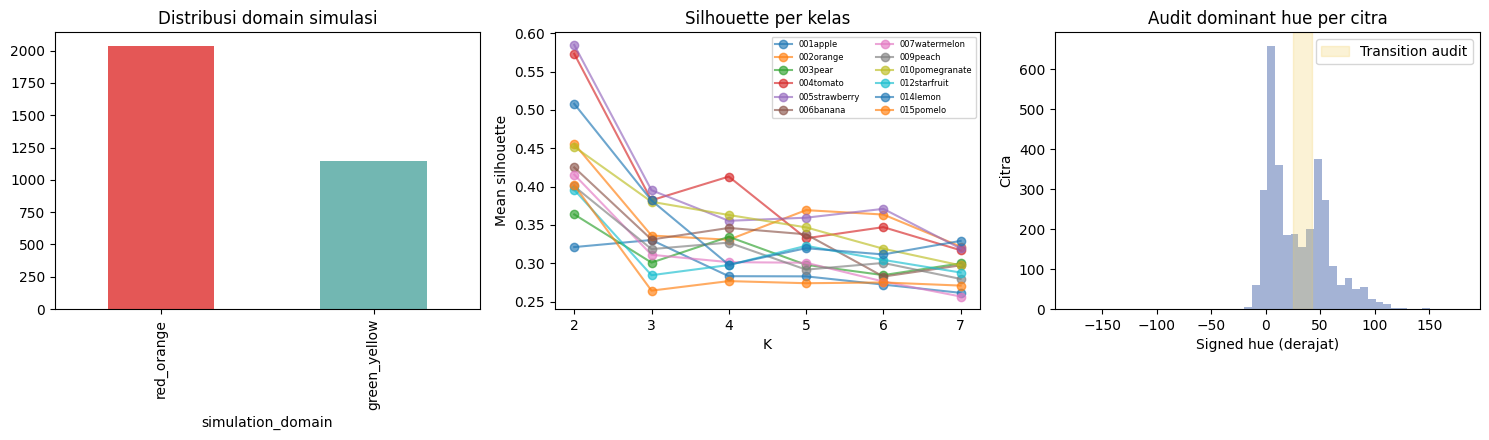

,subset,source_class,source_file_name,source_domain,simulation_domain,hue_range,hue_audit_region,hue_audit_status,domain_matches_source_class,dominant_hue_deg,selected_k,source_path,output_file_name,output_path,output_sha256,processing_seconds,method_version
0,train,001apple,1.png,red_orange,red_orange,red_orange,red_orange,consistent,True,2.131695,3,C:\Colorblind_correction\research\datasets\raw...,001apple__1.png,C:\Colorblind_correction\research\datasets\pro...,e8785be58d7ea938115025c87ac6241ff4e7fd86819448...,0.154358,dataset-preparation-1.5
1,train,001apple,10.png,red_orange,red_orange,red_orange,red_orange,consistent,True,0.039881,3,C:\Colorblind_correction\research\datasets\raw...,001apple__10.png,C:\Colorblind_correction\research\datasets\pro...,40074f5c1797a80ebe5411679977ec2d71637efcff5487...,0.121914,dataset-preparation-1.5
2,train,001apple,100.png,red_orange,red_orange,red_orange,red_orange,consistent,True,19.689144,3,C:\Colorblind_correction\research\datasets\raw...,001apple__100.png,C:\Colorblind_correction\research\datasets\pro...,8c6443d0cadd55d26c15b0edd21fe50b142f3e09bb394b...,0.125771,dataset-preparation-1.5
3,train,001apple,101.png,red_orange,red_orange,red_orange,red_orange,consistent,True,357.468231,3,C:\Colorblind_correction\research\datasets\raw...,001apple__101.png,C:\Colorblind_correction\research\datasets\pro...,e9bcdabffc78d6014e664bdbfeeea575a2a53a9f0319cb...,0.141619,dataset-preparation-1.5
4,train,001apple,102.png,red_orange,red_orange,red_orange,red_orange,consistent,True,14.724947,3,C:\Colorblind_correction\research\datasets\raw...,001apple__102.png,C:\Colorblind_correction\research\datasets\pro...,09382ed66d694ab2c2b750780ccbdb05d73df2a6c7e70f...,0.127020,dataset-preparation-1.5


,subset,source_class,source_file_name,source_domain,simulation_domain,hue_range,hue_audit_region,hue_audit_status,domain_matches_source_class,dominant_hue_deg,selected_k,source_path,output_file_name,output_path,output_sha256,processing_seconds,method_version
0,train,001apple,164.png,red_orange,red_orange,red_orange,transition,transition,False,29.080343,3,C:\Colorblind_correction\research\datasets\raw...,001apple__164.png,C:\Colorblind_correction\research\datasets\pro...,7319dd11d1cce6b6ee49967c2b8b4a5c17529f85863510...,0.120916,dataset-preparation-1.5
1,train,001apple,202.png,red_orange,red_orange,red_orange,transition,transition,False,26.671818,3,C:\Colorblind_correction\research\datasets\raw...,001apple__202.png,C:\Colorblind_correction\research\datasets\pro...,db80dae8c346d432bccd251448d416f0e00ab033e21182...,0.155116,dataset-preparation-1.5
2,train,001apple,252.png,red_orange,red_orange,red_orange,transition,transition,False,32.770939,3,C:\Colorblind_correction\research\datasets\raw...,001apple__252.png,C:\Colorblind_correction\research\datasets\pro...,07315d0f07408e0ec2344c0a821483f61a2b2c29f8e035...,0.147955,dataset-preparation-1.5
3,train,001apple,278.png,red_orange,red_orange,red_orange,transition,transition,False,35.149105,3,C:\Colorblind_correction\research\datasets\raw...,001apple__278.png,C:\Colorblind_correction\research\datasets\pro...,bb946bb74104b34c98557c92fd7e83b97229a1dbdc91fe...,0.204562,dataset-preparation-1.5
4,train,001apple,280.png,red_orange,red_orange,red_orange,transition,transition,False,32.625484,3,C:\Colorblind_correction\research\datasets\raw...,001apple__280.png,C:\Colorblind_correction\research\datasets\pro...,99166a8b6053f963cf5677a1685dac3627ac2dca5aed56...,0.149135,dataset-preparation-1.5


,source_class,phash_threshold,retained_records,removed_records,removed_fraction
0,001apple,0,407,1,0.002451
1,001apple,2,400,8,0.019608
2,001apple,4,388,20,0.049020
3,001apple,6,376,32,0.078431
4,001apple,8,362,46,0.112745
5,002orange,0,430,1,0.002320
6,002orange,2,430,1,0.002320
7,002orange,4,423,8,0.018561
8,002orange,6,419,12,0.027842
9,002orange,8,411,20,0.046404


{
  "notebook": "NB01_dataset_preparation",
  "method_version": "dataset-preparation-1.5",
  "formula_source": {
    "perceptual_hash": "DCT-based pHash with Hamming distance; ImageHash implementation",
    "clustering": "Lloyd K-Means objective with k-means++ initialization",
    "kmeans_initialization": "Arthur and Vassilvitskii (2007), k-means++",
    "k_selection": "Rousseeuw (1987), silhouette coefficient",
    "circular_mean": "Mardia and Jupp (1999), Directional Statistics",
    "hue_audit": "Pandey (2024), Otsu followed by maximum-entropy transition thresholds"
  },
  "research_adaptation": {
    "simulation_domain": "prespecified mapping of fruit source classes to red_orange or green_yellow",
    "colour_clustering": "K-Means on standard OpenCV float CIELAB coordinates",
    "hue_measurement": "dominant-cluster circular mean HSV hue per image"
  },
  "implementation_decision": {
    "phash_threshold": 8,
    "phash_threshold_role": "dataset parameter; sensitivity is reported w

In [5]:
report = pd.DataFrame(report_rows).sort_values(COMPOSITE_KEY).reset_index(drop=True)
domain_audit = pd.DataFrame(domain_audit_rows)
if domain_audit.empty:
    domain_audit = pd.DataFrame(columns=report.columns)
else:
    domain_audit = domain_audit.sort_values(COMPOSITE_KEY).reset_index(drop=True)
errors = pd.DataFrame(error_rows, columns=[*COMPOSITE_KEY, "source_path", "error_stage", "error_type", "error_message"])

input_error_audit = summarize_errors(input_errors)
error_audit = summarize_errors(errors)
duplicates = pd.DataFrame(duplicate_rows, columns=["duplicate_path", "similar_to_path", "hamming_distance"])
dedup_sensitivity = pd.DataFrame(dedup_sensitivity_rows).sort_values(["source_class", "phash_threshold"])
k_scores = pd.DataFrame(k_audit).sort_values(["source_class", "k"])
progress = pd.DataFrame(progress_rows).sort_values(PROGRESS_KEY).reset_index(drop=True)

write_csv(report, OUTPUT_DIR / "dataset_preparation_report.csv", COMPOSITE_KEY)
write_csv(progress, PROGRESS_PATH, PROGRESS_KEY)
write_csv(domain_audit, DOMAIN_AUDIT_PATH, COMPOSITE_KEY, allow_empty=True)
write_csv(errors, ERROR_PATH, COMPOSITE_KEY, allow_empty=True)
write_csv(input_error_audit, INPUT_ERROR_AUDIT_PATH, ERROR_AUDIT_KEY, allow_empty=True)
write_csv(error_audit, ERROR_AUDIT_PATH, ERROR_AUDIT_KEY, allow_empty=True)
write_csv(duplicates, OUTPUT_DIR / "deduplication_report.csv", ["duplicate_path"], allow_empty=True)
write_csv(dedup_sensitivity, DEDUP_SENSITIVITY_PATH, ["source_class", "phash_threshold"])
write_csv(k_scores, OUTPUT_DIR / "k_selection_report.csv", ["source_class", "k"])

simulation_distribution = report.groupby("simulation_domain").size().reindex(
    ["red_orange", "green_yellow"], fill_value=0
)
hue_audit_distribution = report.groupby("hue_audit_region").size().reindex(
    ["red_orange", "transition", "green_yellow"], fill_value=0
)
hue_audit_status = report.groupby("hue_audit_status").size().reindex(
    ["consistent", "transition", "cross_domain"], fill_value=0
)
domain_assignment_audit = (
    report.groupby(["simulation_domain", "hue_audit_region", "hue_audit_status"], as_index=False)
    .size().rename(columns={"size": "records"})
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
simulation_distribution.plot.bar(
    ax=axes[0], color=["#e45756", "#72b7b2"], title="Distribusi domain simulasi"
)
for class_name, group in k_scores.groupby("source_class"):
    axes[1].plot(group["k"], group["silhouette"], marker="o", alpha=0.65, label=class_name)
axes[1].set(title="Silhouette per kelas", xlabel="K", ylabel="Mean silhouette")
axes[1].legend(fontsize=6, ncol=2)

plot_hues = report["dominant_hue_deg"].where(
    report["dominant_hue_deg"] <= 180.0, report["dominant_hue_deg"] - 360.0
)
axes[2].hist(plot_hues, bins=50, color="#8da0cb", alpha=0.8)
axes[2].axvspan(
    domain_config["lower_boundary_deg"], domain_config["upper_boundary_deg"],
    color="#f2cf5b", alpha=0.25, label="Transition audit"
)
axes[2].set(title="Audit dominant hue per citra", xlabel="Signed hue (derajat)", ylabel="Citra")
axes[2].legend()

fig.tight_layout()
figure_path = FIGURES_DIR / "dataset_preparation_audit.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

summary = {
    "notebook": "NB01_dataset_preparation",
    "method_version": METHOD_VERSION,
    "formula_source": {
        "perceptual_hash": "DCT-based pHash with Hamming distance; ImageHash implementation",
        "clustering": "Lloyd K-Means objective with k-means++ initialization",
        "kmeans_initialization": "Arthur and Vassilvitskii (2007), k-means++",
        "k_selection": "Rousseeuw (1987), silhouette coefficient",
        "circular_mean": "Mardia and Jupp (1999), Directional Statistics",
        "hue_audit": "Pandey (2024), Otsu followed by maximum-entropy transition thresholds",
    },
    "research_adaptation": {
        "simulation_domain": "prespecified mapping of fruit source classes to red_orange or green_yellow",
        "colour_clustering": "K-Means on standard OpenCV float CIELAB coordinates",
        "hue_measurement": "dominant-cluster circular mean HSV hue per image",
    },
    "implementation_decision": {
        "phash_threshold": PHASH_THRESHOLD,
        "phash_threshold_role": "dataset parameter; sensitivity is reported without changing the pHash formula",
        "hue_range_compatibility_alias": "same value as simulation_domain for downstream notebooks",
        "hue_audit_policy": "audit only; transition and cross-domain records remain in the manifest",
        "undersampling": False,
    },
    "parameters": {
        "random_seed": RANDOM_SEED,
        "phash_threshold": PHASH_THRESHOLD,
        "phash_sensitivity_thresholds": list(PHASH_SENSITIVITY_THRESHOLDS),
        "target_size": list(TARGET_SIZE),
        "cluster_size": CLUSTER_SIZE,
        "k_range": [min(K_RANGE), max(K_RANGE)],
        "kmeans_init": KMEANS_INIT,
        "kmeans_n_init": KMEANS_N_INIT,
        "kmeans_algorithm": KMEANS_ALGORITHM,
        "kmeans_max_iter": KMEANS_MAX_ITER,
        "kmeans_tolerance": KMEANS_TOL,
        "k_sample_images": K_SAMPLE_IMAGES,
        "k_pixels_per_image": K_PIXELS_PER_IMAGE,
        "silhouette_sample": SILHOUETTE_SAMPLE,
        "image_cluster_pixels": IMAGE_CLUSTER_PIXELS,
        "saturation_min": SATURATION_MIN,
        "value_range": [VALUE_MIN, VALUE_MAX],
        "hue_audit_boundaries_deg": [domain_config["lower_boundary_deg"], domain_config["upper_boundary_deg"]],
        "domain_method_version": domain_config["method_version"],
    },
    "sample_counts": {
        "raw_candidates": int(sum(len(train_images(name)) for name in SOURCE_CLASSES)),
        "after_dedup": int(total_candidates),
    },
    "record_counts": {
        "report": int(len(report)), "domain_audit": int(len(domain_audit)), "errors": int(len(errors)),
        "progress_checkpoints": int(len(progress)),
        "duplicates_removed": int(len(duplicates)), "dedup_sensitivity": int(len(dedup_sensitivity)),
        "input_errors_audited": int(len(input_errors)),
    },
    "statistics": {
        "simulation_distribution": {key: int(value) for key, value in simulation_distribution.items()},
        "hue_audit_distribution": {key: int(value) for key, value in hue_audit_distribution.items()},
        "hue_audit_status": {key: int(value) for key, value in hue_audit_status.items()},
        "domain_assignment_audit": domain_assignment_audit.to_dict(orient="records"),
        "deduplication_sensitivity": dedup_sensitivity.to_dict(orient="records"),
        "median_processing_seconds": float(report["processing_seconds"].median()) if len(report) else 0.0,
        "input_error_audit": input_error_audit.to_dict(orient="records"),
        "current_error_audit": error_audit.to_dict(orient="records"),
    },
    "output_contract": {
        "balanced": False, "manifest_is_source_of_truth": True,
        "simulation_assignment": "source_class_to_source_domain",
        "hue_audit_is_independent": True,
        "all_successful_records_in_manifest": True,
        "composite_key": COMPOSITE_KEY,
        "progress_is_checkpoint_log": True,
        "progress_composite_key": PROGRESS_KEY,
    },
    "outputs": {
        "image_dir": str(IMAGE_DIR), "report_csv": str(OUTPUT_DIR / "dataset_preparation_report.csv"),
        "progress_csv": str(PROGRESS_PATH),
        "domain_audit_csv": str(DOMAIN_AUDIT_PATH), "error_csv": str(ERROR_PATH),
        "input_error_audit_csv": str(INPUT_ERROR_AUDIT_PATH), "error_audit_csv": str(ERROR_AUDIT_PATH),
        "deduplication_csv": str(OUTPUT_DIR / "deduplication_report.csv"),
        "deduplication_sensitivity_csv": str(DEDUP_SENSITIVITY_PATH),
        "k_selection_csv": str(OUTPUT_DIR / "k_selection_report.csv"),
        "figure": str(figure_path),
    },
    "software_versions": software_versions(),
    "created_at": utc_timestamp(),
}
write_json(summary, OUTPUT_DIR / "dataset_preparation_summary.json")
display(report.head())
display(domain_audit.head())
display(dedup_sensitivity)
print(json.dumps(summary, indent=2, ensure_ascii=False))
